In [2]:
# Load libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [4]:
df= pd.read_csv(r"C:\Users\ADMIN\Desktop\Protein Stability\Data\4_fireprotDB_bestpH.csv")
df.head(1)

,Unnamed: 0,experiment_id,protein_name,uniprot_id,pdb_id,chain,position,wild_type,mutation,ddG,...,hsw_job_id,datasets,sequence,pdb_id_corrected,dupe_detector,pdb_position,pdb_sequence,oligomeric_state,structure_method,resolution
0,23,LL000714,Immunoglobulin G-binding protein G,P06654,1PGA|1EM7|2GB1,A,1,M,A,-0.14,...,2i1nqi,NaN,MEKEKKVKYFLRKSAFGLASVSAAFLVGSTVFAVDSPIEDTPIIRN...,1PGA,1PGA-A-0-M-P06654,0,MTYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGVDGEWTYD...,monomer,x-ray diffraction,NaN


In [5]:
# Remove rows without the target
df = df.dropna(subset=["ddG"]).copy()

# Select features
features = [
    "wild_type",
    "mutation",
    "position",
    "secondary_structure",
    "conservation",
    "is_back_to_consensus",
    "is_essential"
]

X = df[features]
y = df["ddG"]
groups = df["uniprot_id"]

# Identify feature types
categorical_features = [
    "wild_type",
    "mutation",
    "secondary_structure"
]
numeric_features = [
    "position",
    "conservation",
    "is_back_to_consensus",
    "is_essential"
]

# Preprocessing
preprocessor = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features),

    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numeric_features)
])

# Split by protein
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]



In [6]:
# Define models
models = {"Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200,random_state=42),
    "SVR": SVR(kernel="rbf"),
    "XGBoost": XGBRegressor(n_estimators=200,max_depth=4,learning_rate=0.05,random_state=42)

}

results = []
trained_models = {}

# Train and evaluate each model
for name, regressor in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    # Train each model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Evaluate
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # storing the result
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model

    print(f"\n{name}")
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))


Linear Regression
MAE: 1.1373
RMSE: 1.5189
R2 Score: 0.1617

Random Forest
MAE: 1.2718
RMSE: 1.6909
R2 Score: -0.039

SVR
MAE: 1.2429
RMSE: 1.6567
R2 Score: 0.0026

XGBoost
MAE: 1.1291
RMSE: 1.4853
R2 Score: 0.1983


In [7]:

print("====Final Model Comparison====")
Performance_result = pd.DataFrame(results)
Performance_result = Performance_result.sort_values(by ="MAE", ascending= True)

print(Performance_result)


====Final Model Comparison====
               Model       MAE      RMSE  R2 Score
3            XGBoost  1.129054  1.485342  0.198321
0  Linear Regression  1.137327  1.518901  0.161687
2                SVR  1.242947  1.656736  0.002635
1      Random Forest  1.271792  1.690926 -0.038955


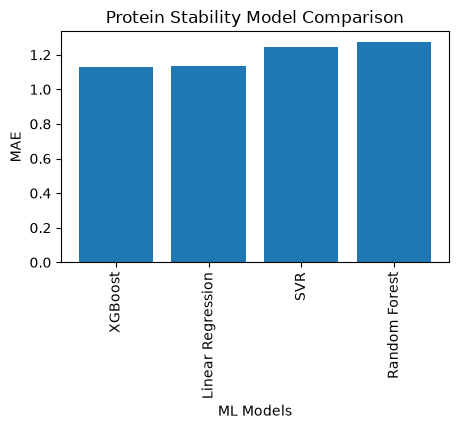

In [8]:
# Visualize the comparison
plt.figure(figsize=(5,3))

plt.bar(Performance_result['Model'], Performance_result['MAE'])
plt.title("Protein Stability Model Comparison")
plt.xlabel("ML Models")
plt.ylabel("MAE")
plt.xticks(rotation=90)
plt.show()

In [14]:
# Select the best model
best_model_name = Performance_result.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print("Best model based on MAE:", best_model_name)

import os
# Create the folder if it doesn't exist
os.makedirs("Model_comparison", exist_ok=True)

# Save comparison result in csv
Performance_result.to_csv("Model_comparison/Comparison Result of Models", index=False)

Best model based on MAE: XGBoost


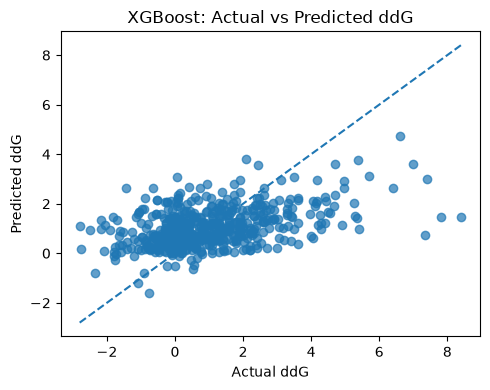

In [10]:
# Actual Vs Predicaiton values
best_model = trained_models["XGBoost"]
y_pred = best_model.predict(X_test)

plt.figure(figsize=(5, 4))
plt.scatter(y_test, y_pred, alpha=0.7)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual ddG")
plt.ylabel("Predicted ddG")
plt.title("XGBoost: Actual vs Predicted ddG")
plt.tight_layout()
plt.show()

In [15]:
# Save model
import joblib
import os

# Create the folder if it doesn't exist
os.makedirs("Model", exist_ok=True)


joblib.dump(best_model, "Model/Protein_stability_model.pkl")
print("Model Save Successfully")

Model Save Successfully


In [17]:
# Create a file 
sample = pd.DataFrame({
    "wild_type": ["A"],
    "mutation": ["V"],
    "position": [25],
    "secondary_structure": ["H"],
    "conservation": [0.85],
    "is_back_to_consensus": [1],
    "is_essential": [0]
})

sample.to_csv(
    "sample_input.csv",
    index=False
)

print("Sample input file created!")

Sample input file created!


In [ ]:
# Checking the csv file exist or not.

import os
print(os.path.exists("sample_input.csv"))
print(os.listdir())

True
['.venv', '01_data_exploration.py', '4_fireprotDB_bestpH.csv', 'Comparison Result of Models', 'fireprot_upload', 'project_with_less_features.ipynb', 'project_with_more_features.ipynb', 'Protein_stability_model.pkl', 'readme.txt', 'requirements.txt', 'sample_input.csv']


In [27]:
# Load the saved model
loaded_model = joblib.load("Protein_stability_model.pkl")

# Load sample input
new_sample = pd.read_csv( "sample_input.csv")

# Predict ddG
predicted_ddG = loaded_model.predict(new_sample)

print("Predicted ddG:", predicted_ddG[0])


Predicted ddG: 0.49607265


In [29]:
new_sample.head()

,wild_type,mutation,position,secondary_structure,conservation,is_back_to_consensus,is_essential
0,A,V,25,H,0.85,1,0


### In Protein Stability Prediction project, `ddG (ΔΔG)` means the change in Gibbs free energy between a mutant protein and its wild-type protein. 
###### This is useful to study whether a mutation changes protein stability.

##### What does ddG mean?
##### ΔG (delta G): Gibbs free energy associated with protein folding or unfolding, depending on the convention.
##### ΔΔG (delta-delta G): The difference in that free energy between a mutant and a reference (wild-type) protein.

##### Protein stability is:
##### [ΔΔG stability = ΔG mutant - ΔG wild type
### Here, ΔG stability is defined as the free energy of unfolding minus the free energy of folding. 
####  With this definition, a `positive ddG` indicates `reduced stability`, 
#### while a `negative ddG` indicates `increased stability`.
### However, some datasets use the opposite sign convention, so you must check your dataset's documentatio